In [1]:
import os
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "nn").exists() else Path.cwd().parent
os.chdir(ROOT)

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from nn import *
from nn.data import load_image_folder, one_hot
from nn.visualizations import plot_history, plot_digits, plot_confusion_matrix

In [3]:
os.getcwd()

'/Users/arjunadhithyarr/Documents/z-arjun/numpy-neural-net-play'

# MNIST digits with the from-scratch network

Same engine as the moons notebook, now on handwritten digits: 28×28 grayscale images, 10 classes.

1. load the images from `data/mnist_images`
2. turn each image into 784 numbers and each label into a one-hot vector
3. build `784 -> 32 tanh -> 10 sigmoid`
4. one step by hand, then train
5. look at what it gets right and wrong
6. why the starting weights have to be small
7. save and reload a checkpoint

## 1. Load the images

Each file is named `digit_<label>_idx_<n>.png`, so the label comes from the filename. Pixels are already between 0 (black) and 1 (white).

In [4]:
X_train, y_train = load_image_folder("data/mnist_images/train")
X_test, y_test = load_image_folder("data/mnist_images/test")

print("train", X_train.shape, "  test", X_test.shape, "  pixels", X_train.min(), "to", X_train.max())
print("train images per digit", np.bincount(y_train, minlength=10))
print("test images per digit ", np.bincount(y_test, minlength=10))

train (50, 784)   test (50, 784)   pixels 0.0 to 1.0
train images per digit [4 7 4 7 4 4 5 4 4 7]
test images per digit  [5 9 5 4 9 4 3 6 0 5]


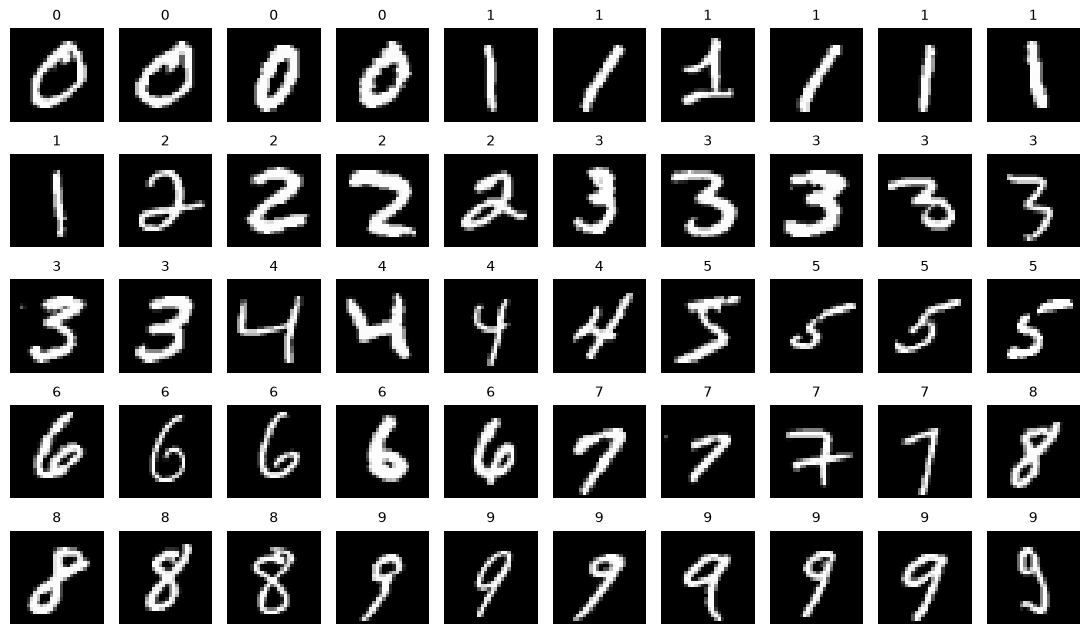

In [5]:
plot_digits(X_train, y_train)

## 2. Images in, one-hot labels out

The network sees an image as one row of 784 pixel values (28 × 28, row by row). It has 10 outputs, one per digit, each a sigmoid answering "is this digit k?". So the target for a `3` is ten numbers with a 1 in position 3. The predicted digit is whichever output is largest.

In [6]:
Y_train = one_hot(y_train, 10)
Y_test = one_hot(y_test, 10)

print("one image  ", X_train[0].shape)
print("label      ", y_train[0])
print("one-hot    ", Y_train[0])

one image   (784,)
label       0
one-hot     [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 3. Build the network

`784 -> 32 tanh -> 10 sigmoid`, trained with binary cross-entropy on the ten outputs.

The weights are passed in instead of using `multipleNeuron`'s default `randn`. Each hidden neuron sums 784 inputs, so standard-normal weights make `z` large and the tanh saturates at ±1, where its slope is almost zero and learning stalls. Scaling each layer's starting weights by `1 / sqrt(n_inputs)` keeps `z` near the useful range. Section 6 shows the difference.

In [7]:
def build_net(hidden=32, scaled=True, seed=0):
    rng = np.random.default_rng(seed)
    s1 = 1 / np.sqrt(784) if scaled else 1.0
    s2 = 1 / np.sqrt(hidden) if scaled else 1.0
    return stackLayers([
        multipleNeuron(n=hidden, n_inputs=784, activation=tanh,
                       W=rng.normal(0, s1, (hidden, 784)), b=np.zeros(hidden)),
        multipleNeuron(n=10, n_inputs=hidden, activation=sigmoid,
                       W=rng.normal(0, s2, (10, hidden)), b=np.zeros(10)),
    ])

net = build_net()
loss_fn = binary_cross_entropy
lr = 0.1

print(net)
loss, acc = evaluate(net, X_test, Y_test, loss_fn)
print(f"untrained  test loss {loss:.4f}  test acc {acc:.2f}  (guessing is about 0.10)")

stackLayers(784 -> 32 tanh -> 10 sigmoid)
untrained  test loss 0.7092  test acc 0.08  (guessing is about 0.10)


## 4. One step by hand, then train

One image through forward, loss, backward, update. The loss on that image should drop.

In [8]:
x0, t0 = X_train[0], Y_train[0]

pred = net.forward(x0)
loss_before = loss_fn(t0, pred)
print("true digit", y_train[0], "  predicted", pred.argmax())
print("outputs   ", np.round(pred, 3))

net.backward(binary_cross_entropy_derivative(t0, pred))
sgd_step(net, lr)

loss_after = loss_fn(t0, net.forward(x0))
print(f"loss on this image {float(loss_before):.4f} -> {float(loss_after):.4f}")

true digit 0   predicted 2
outputs    [0.327 0.494 0.659 0.594 0.419 0.518 0.556 0.498 0.536 0.445]
loss on this image 0.7903 -> 0.5679


In [9]:
history = train(net, X_train, Y_train, loss_fn, lr=lr, epochs=200,
                X_val=X_test, Y_val=Y_test, log_every=10, seed=0)

epoch    1  loss 0.3166  acc 0.300  val_loss 0.3410  val_acc 0.200
epoch   10  loss 0.1323  acc 0.980  val_loss 0.2147  val_acc 0.700
epoch   20  loss 0.0629  acc 1.000  val_loss 0.1834  val_acc 0.700


epoch   30  loss 0.0365  acc 1.000  val_loss 0.1735  val_acc 0.640
epoch   40  loss 0.0246  acc 1.000  val_loss 0.1715  val_acc 0.640
epoch   50  loss 0.0183  acc 1.000  val_loss 0.1719  val_acc 0.640


epoch   60  loss 0.0144  acc 1.000  val_loss 0.1727  val_acc 0.640
epoch   70  loss 0.0118  acc 1.000  val_loss 0.1739  val_acc 0.640
epoch   80  loss 0.0099  acc 1.000  val_loss 0.1752  val_acc 0.640


epoch   90  loss 0.0086  acc 1.000  val_loss 0.1766  val_acc 0.640
epoch  100  loss 0.0075  acc 1.000  val_loss 0.1779  val_acc 0.660
epoch  110  loss 0.0067  acc 1.000  val_loss 0.1793  val_acc 0.660


epoch  120  loss 0.0060  acc 1.000  val_loss 0.1804  val_acc 0.680
epoch  130  loss 0.0055  acc 1.000  val_loss 0.1816  val_acc 0.680
epoch  140  loss 0.0050  acc 1.000  val_loss 0.1827  val_acc 0.680


epoch  150  loss 0.0046  acc 1.000  val_loss 0.1836  val_acc 0.680
epoch  160  loss 0.0043  acc 1.000  val_loss 0.1846  val_acc 0.660
epoch  170  loss 0.0040  acc 1.000  val_loss 0.1856  val_acc 0.660


epoch  180  loss 0.0037  acc 1.000  val_loss 0.1865  val_acc 0.660
epoch  190  loss 0.0035  acc 1.000  val_loss 0.1873  val_acc 0.660
epoch  200  loss 0.0033  acc 1.000  val_loss 0.1882  val_acc 0.660


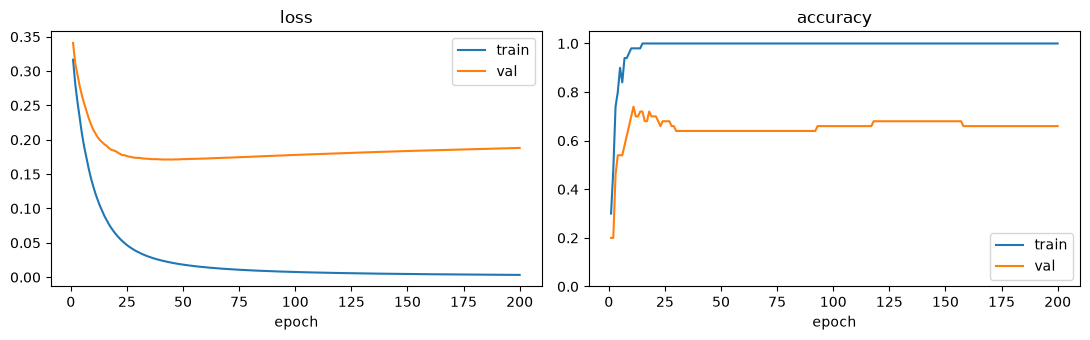

In [10]:
plot_history(history)

## 5. What it gets right and wrong

Training accuracy reaches 100% while test accuracy stays far lower. With only 4 to 7 training images per digit, the network memorizes those exact images rather than learning what a digit looks like in general. The curves above show it: test accuracy peaks early, then slips while training loss keeps falling. More training images is the biggest improvement available.

In the grid, green is correct. Red shows the prediction, with the true digit in brackets.

train accuracy 1.00  (50/50)
test accuracy  0.66  (33/50)


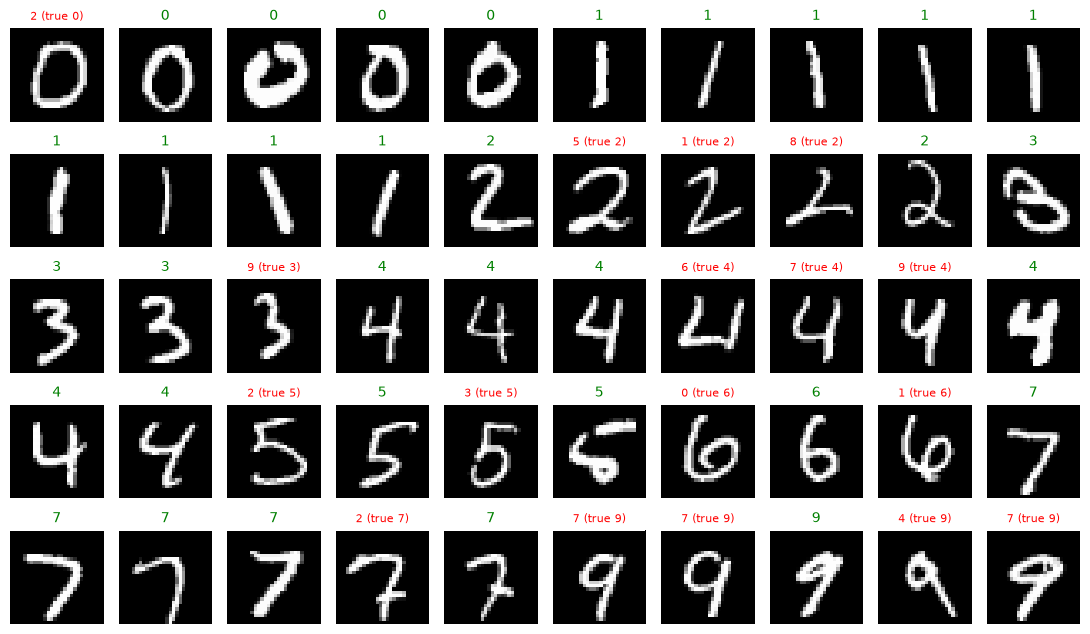

In [11]:
train_pred = predict(net, X_train).argmax(axis=1)
test_pred = predict(net, X_test).argmax(axis=1)
print(f"train accuracy {np.mean(train_pred == y_train):.2f}  ({np.sum(train_pred == y_train)}/{len(y_train)})")
print(f"test accuracy  {np.mean(test_pred == y_test):.2f}  ({np.sum(test_pred == y_test)}/{len(y_test)})")

plot_digits(X_test, y_test, test_pred)

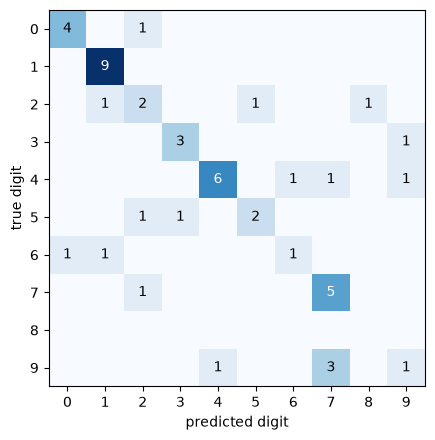

In [12]:
# rows are the true digit, columns the prediction; everything off the diagonal is a mistake
plot_confusion_matrix(y_test, test_pred)

## 6. Why the starting weights have to be small

Two fresh networks, identical except for the starting weight scale. Before training, count how many hidden tanh outputs are already stuck past ±0.99. Then train both the same way and compare test accuracy.

In [13]:
def saturated_fraction(net, X):
    hidden = []
    for x in X:
        net.forward(x)
        hidden.append([n.out for n in net.layers[0].neurons])
    return np.mean(np.abs(hidden) > 0.99)

for scaled in (True, False):
    candidate = build_net(scaled=scaled)
    stuck = saturated_fraction(candidate, X_train)
    train(candidate, X_train, Y_train, loss_fn, lr=lr, epochs=60, log_every=0, seed=0)
    _, acc = evaluate(candidate, X_test, Y_test, loss_fn)
    label = "1/sqrt(n_inputs)" if scaled else "standard normal"
    print(f"{label:<17}  saturated at start {stuck:.0%}   test acc after training {acc:.2f}")

1/sqrt(n_inputs)   saturated at start 0%   test acc after training 0.64


standard normal    saturated at start 77%   test acc after training 0.18


## 7. Save and reload a checkpoint

In [14]:
ckpt_path = save_checkpoint(
    net, "checkpoints/mnist_784-32-10",
    epoch=history["epoch"][-1], lr=lr,
    train_accuracy=history["accuracy"][-1], test_accuracy=history["val_accuracy"][-1],
    history=history,
)
restored, meta = load_checkpoint(ckpt_path)

print(ckpt_path)
print(restored, "  epoch", meta["epoch"], "  test acc", meta["test_accuracy"])
print("same predictions:", np.allclose(predict(net, X_test), predict(restored, X_test)))

checkpoints/mnist_784-32-10.npz
stackLayers(784 -> 32 tanh -> 10 sigmoid)   epoch 200   test acc 0.66
same predictions: True


## Things to try

- more images in `data/mnist_images/train`, named the same way. This will move test accuracy more than anything else.
- 16 or 64 hidden neurons instead of 32
- `relu` in the hidden layer
- `lr` of `0.5` or `0.02`
- `mean_squared_error` instead of binary cross-entropy